# 01 · Focusing in water

A quick tour of the `hifu_sim` API on a small grid (runs in a few seconds):

1. build a grid, a homogeneous water medium and a 32-element arc transducer,
2. run a continuous-wave FDTD simulation to steady state,
3. compare the focal gain and focal width with the 2D diffraction integral,
4. steer the focus electronically with per-element delays.

In [1]:
import math
import time

import matplotlib.pyplot as plt
import numpy as np

import hifu_sim as hs
from hifu_sim.plotting import plot_amplitude, style

print("hifu-sim", hs.__version__, "| numba available:", hs.NUMBA_AVAILABLE)

hifu-sim 0.1.0 | numba available: True


## Set-up

0.75 MHz in water gives a 2 mm wavelength; a 0.15 mm grid spacing resolves it with ~13 points
per wavelength. The PML (20 cells) is inside the grid, so the usable region is a bit smaller
than the grid.

In [2]:
f0, c0 = 0.75e6, 1500.0
grid = hs.Grid.from_size(0.045, 0.040, 1.5e-4)
medium = hs.Medium.homogeneous(grid, "water", f0)
transducer = hs.ArcTransducer(
    frequency=f0, radius=0.028, aperture_deg=70, focus=(0.034, 0.020), amplitude=1e5, n_elements=32
)
sim = hs.Simulation(grid, medium, f0, pml=hs.PML(20), cfl=0.3)
sim.add_source(transducer.to_source(grid, c0))
print(f"grid {grid.nx} x {grid.ny}, dt = {sim.dt * 1e9:.1f} ns, backend = {sim.backend}")
print(f"CFL limit c*dt/dx < {hs.cfl_limit(grid.dx):.3f}; used {medium.c_max * sim.dt / grid.dx:.3f}")

grid 300 x 267, dt = 29.6 ns, backend = numba
CFL limit c*dt/dx < 0.707; used 0.296


In [3]:
t0 = time.perf_counter()
result = sim.run_cw(record_periods=4)
print(f"{result.n_steps} steps in {time.perf_counter() - t0:.2f} s")
metrics = hs.focal_metrics(result, transducer)
{k: round(v, 6) for k, v in metrics.items()}

1942 steps in 2.38 s


{'peak_x_m': 0.032925,
 'peak_y_m': 0.020025,
 'target_x_m': 0.034,
 'target_y_m': 0.02,
 'axial_offset_m': -0.001075,
 'lateral_offset_m': 2.5e-05,
 'peak_amplitude_Pa': 456362.862215,
 'focal_gain': 4.563629,
 'peak_intensity_W_m2': 69422.354003,
 'peak_positive_Pa': 456870.840062,
 'peak_negative_Pa': -458321.78532,
 'fwhm_axial_m': 0.012805,
 'fwhm_lateral_m': 0.002001,
 'dt_s': 0.0,
 'n_steps': 1942.0,
 'elapsed_s': 2.376444}

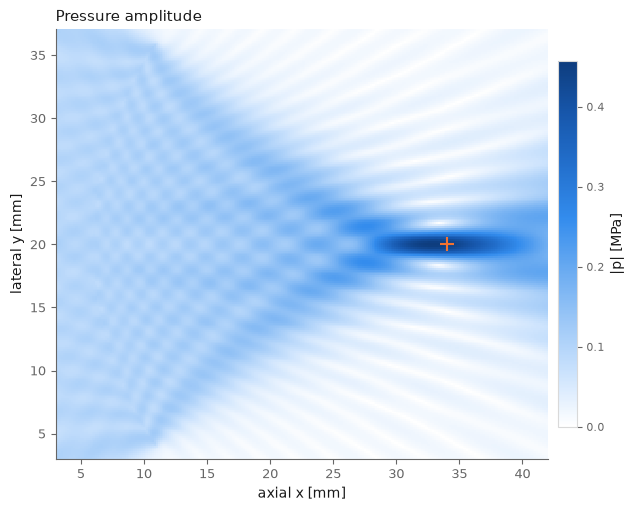

In [4]:
with style():
    fig, ax = plt.subplots(figsize=(6.5, 5), constrained_layout=True)
    plot_amplitude(ax, result, transducer.target)
plt.show()

## Comparison with the 2D Rayleigh integral

Each arc element of length $ds$ at distance $R$ from the focus contributes
$p_0\sqrt{k/(2\pi R)}\,ds$ in phase, so the gain at the geometric focus is
$G = L/\sqrt{\lambda R}$ with $L$ the arc length. Laterally, the focal-plane profile is
$|\int_{-\theta}^{\theta} e^{iky\sin\varphi}\,d\varphi|$.

gain at geometric focus: FDTD 4.479, theory 4.571 (-2.0 %)


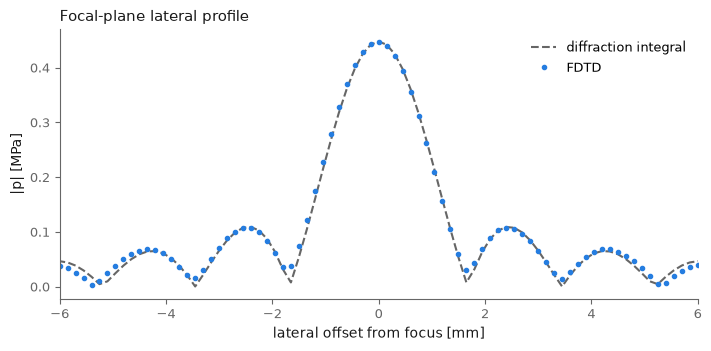

-6 dB width: FDTD 2.07 mm, theory 2.04 mm


In [5]:
i, j = grid.index_of(*transducer.focus)
gain_sim = result.amplitude[i, j] / transducer.amplitude
gain_theory = transducer.focal_gain_estimate(c0)
print(f"gain at geometric focus: FDTD {gain_sim:.3f}, theory {gain_theory:.3f} "
      f"({100 * (gain_sim / gain_theory - 1):+.1f} %)")

k = 2 * math.pi * f0 / c0
half = transducer.half_angle
phi = np.linspace(-half, half, 2001)
y = grid.y - grid.y[j]
theory = np.abs(np.exp(1j * k * y[:, None] * np.sin(phi)).sum(axis=1))
theory *= result.amplitude[i, j] / theory.max()

with style():
    fig, ax = plt.subplots(figsize=(7, 3.4), constrained_layout=True)
    ax.plot(y * 1e3, theory / 1e6, color="#666666", ls="--", lw=1.5, label="diffraction integral")
    ax.plot(y * 1e3, result.amplitude[i, :] / 1e6, "o", ms=3, color="#257de0", label="FDTD")
    ax.set_xlim(-6, 6)
    ax.set_xlabel("lateral offset from focus [mm]")
    ax.set_ylabel("|p| [MPa]")
    ax.set_title("Focal-plane lateral profile", loc="left")
    ax.legend()
plt.show()
print(f"-6 dB width: FDTD {hs.width_at_level(result.amplitude[i, :], grid.dx) * 1e3:.2f} mm, "
      f"theory {hs.width_at_level(theory, grid.dx) * 1e3:.2f} mm")

## Electronic steering

With `steer` set, every element is delayed so all wavefronts reach the new target together.
The peak moves to the target and loses a little amplitude (the elements no longer face it).

target y = 24.00 mm, peak at y = 23.92 mm, gain 4.51 (unsteered 4.56)


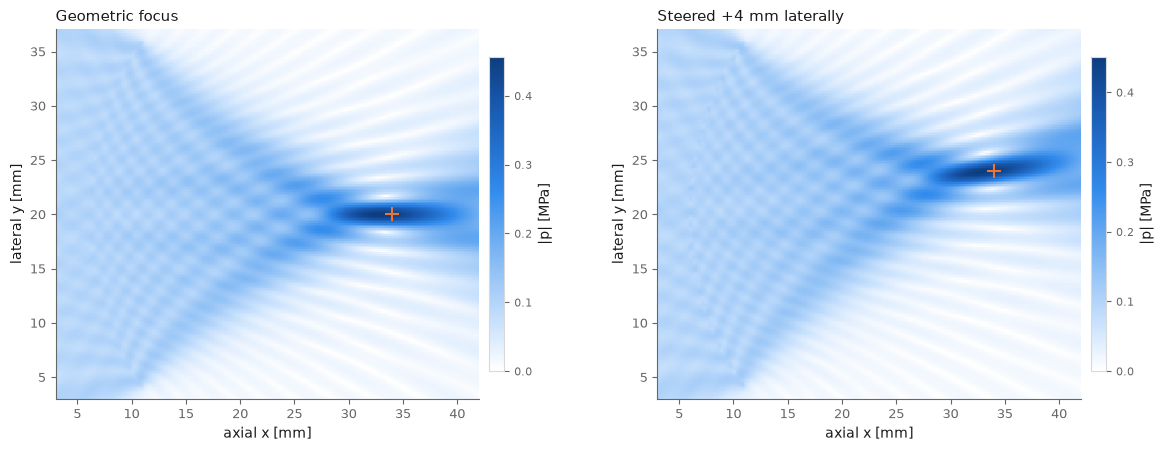

In [6]:
steered = hs.ArcTransducer(
    frequency=f0, radius=0.028, aperture_deg=70, focus=(0.034, 0.020), amplitude=1e5,
    n_elements=32, steer=(0.0, 4e-3),
)
sim2 = hs.Simulation(grid, medium, f0, pml=hs.PML(20), cfl=0.3)
sim2.add_source(steered.to_source(grid, c0))
result2 = sim2.run_cw()
m2 = hs.focal_metrics(result2, steered)
print(f"target y = {steered.target[1] * 1e3:.2f} mm, peak at y = {m2['peak_y_m'] * 1e3:.2f} mm, "
      f"gain {m2['focal_gain']:.2f} (unsteered {metrics['focal_gain']:.2f})")
with style():
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), constrained_layout=True)
    plot_amplitude(axes[0], result, transducer.target, title="Geometric focus")
    plot_amplitude(axes[1], result2, steered.target, title="Steered +4 mm laterally")
plt.show()

## Kernel back-ends

The same step is available as a vectorised NumPy kernel and a multithreaded Numba kernel
(if Numba is installed). They produce the same numbers; only the speed differs.

In [7]:
def run_steps(backend, n=300):
    s = hs.Simulation(grid, medium, f0, pml=hs.PML(20), backend=backend)
    s.add_source(transducer.to_source(grid, c0))
    s.run(5)  # warm-up / JIT compile
    t = time.perf_counter()
    s.run(n)
    return s.pressure, (time.perf_counter() - t) / n


p_np, t_np = run_steps("numpy")
print(f"numpy: {t_np * 1e3:.3f} ms/step")
if hs.NUMBA_AVAILABLE:
    p_nb, t_nb = run_steps("numba")
    print(f"numba: {t_nb * 1e3:.3f} ms/step, max |difference| = {np.abs(p_nb - p_np).max():.2e} Pa")

numpy: 0.561 ms/step
numba: 0.151 ms/step, max |difference| = 0.00e+00 Pa
